# Rice Leaf Disease Detection Using Deep Learning

## Project Overview

This project focuses on detecting and classifying diseases in rice plant leaves using deep learning-based image classification techniques.

The dataset contains images belonging to three rice leaf disease classes:

- Leaf Smut
- Brown Spot
- Bacterial Leaf Blight

The project includes data analysis, image preprocessing, data augmentation, deep learning model development, model evaluation, model comparison, and selection of the best-performing model.

## 1. Problem Statement

Rice plants can be affected by different diseases that may reduce crop quality and productivity.

The objective of this project is to develop an image classification system that can classify rice leaf images into three disease categories:

- Leaf Smut
- Brown Spot
- Bacterial Leaf Blight

Different deep learning techniques and data augmentation methods are applied and evaluated to obtain an effective disease classification model.

## 2. Objectives

- Analyze the rice leaf image dataset.
- Understand the distribution of disease classes.
- Visualize sample rice leaf images.
- Preprocess images for deep learning.
- Apply data augmentation techniques.
- Build multiple image classification models.
- Evaluate model performance using suitable metrics.
- Compare the performance of different models.
- Select the best-performing model.
- Document challenges faced and the techniques used to address them.

## Import Libraries

In [3]:
import os
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

print("Basic libraries imported successfully")

Basic libraries imported successfully


In [4]:
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 3. Dataset Description

The dataset consists of rice leaf images belonging to three disease classes:

- Leaf Smut
- Brown Spot
- Bacterial Leaf Blight

The project document describes the dataset as containing 120 images with 40 images per class.

The uploaded dataset archive was also inspected before modelling. The actual archive contains 119 image files: 39 Leaf Smut images, 40 Brown Spot images, and 40 Bacterial Leaf Blight images.

Therefore, the analysis and modelling in this notebook are based on the actual available images.

## 4. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the number of images in each disease class, visualize representative images, and examine the image dimensions.

### 4.1 Dataset Summary

The dataset contains images of rice leaves affected by different diseases.

The available images are organized into three disease classes:

- Leaf Smut
- Brown Spot
- Bacterial Leaf Blight

The actual number of images available in the dataset is calculated programmatically to ensure that the analysis is based on the available data.

In [5]:
import os
import pandas as pd

dataset_folder = r"C:\Users\saila\Downloads"

class_folders = [
    "Leaf smut-20200814T055530Z-001",
    "Brown spot-20200814T055208Z-001",
    "Bacterial leaf blight-20200814T055237Z-001"
]

class_names = [
    "Leaf Smut",
    "Brown Spot",
    "Bacterial Leaf Blight"
]

data = []

for folder, class_name in zip(class_folders, class_names):
    class_path = os.path.join(dataset_folder, folder)

    for root, dirs, files in os.walk(class_path):
        for file_name in files:
            if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
                data.append({
                    "image_path": os.path.join(root, file_name),
                    "class": class_name
                })

df = pd.DataFrame(data)

print("Total images:", len(df))
print("\nImages in each class:")
print(df["class"].value_counts())

Total images: 119

Images in each class:
class
Brown Spot               40
Bacterial Leaf Blight    40
Leaf Smut                39
Name: count, dtype: int64


### 4.2 Class Distribution

The distribution of images across the three disease classes is analyzed to understand the class balance of the dataset.

In [6]:
class_counts = df["class"].value_counts()

print("Number of images in each class:")
print(class_counts)

Number of images in each class:
class
Brown Spot               40
Bacterial Leaf Blight    40
Leaf Smut                39
Name: count, dtype: int64


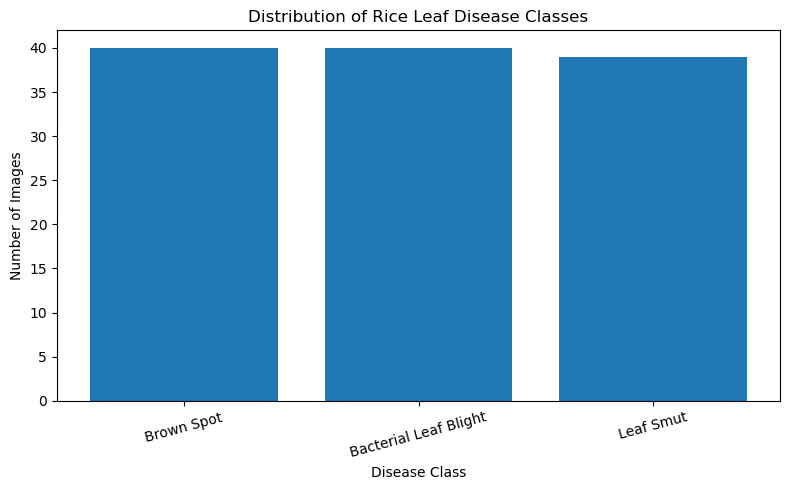

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(class_counts.index, class_counts.values)
plt.title("Distribution of Rice Leaf Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 4.3 Sample Image Visualization

Representative images from each disease class are visualized to understand the visual characteristics of the rice leaf diseases.

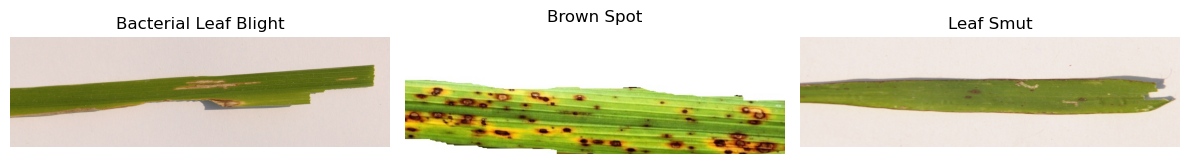

In [8]:
from PIL import Image
import matplotlib.pyplot as plt

classes = sorted(df["class"].unique())

plt.figure(figsize=(12, 4))

for i, class_name in enumerate(classes):
    sample = df[df["class"] == class_name].iloc[0]
    image = Image.open(sample["image_path"])

    plt.subplot(1, len(classes), i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### 4.4 Image Dimension Analysis

The dimensions of the available images are analyzed to understand the variation in image width and height before preprocessing.

In [9]:
dimensions = []

for path in df["image_path"]:
    with Image.open(path) as img:
        dimensions.append({
            "Width": img.width,
            "Height": img.height
        })

dimension_df = pd.DataFrame(dimensions)

dimension_df.describe()

,Width,Height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000


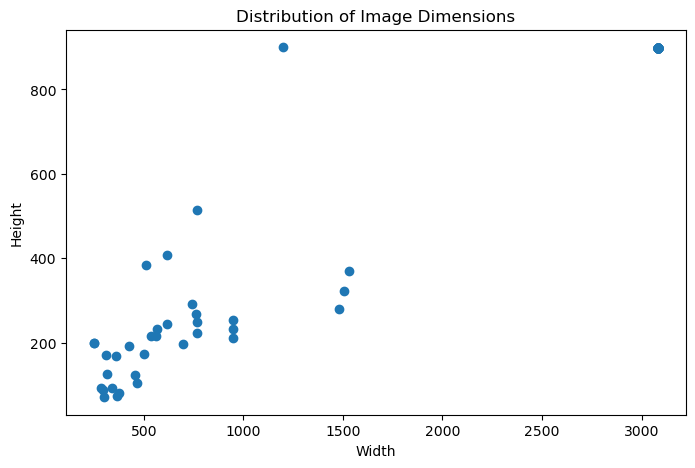

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    dimension_df["Width"],
    dimension_df["Height"]
)

plt.title("Distribution of Image Dimensions")
plt.xlabel("Width")
plt.ylabel("Height")
plt.show()

## 5 Data Preprocessing

In [11]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["class"], random_state=42
)

validation_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["class"], random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Test images:", len(test_df))

Training images: 83
Validation images: 18
Test images: 18


### 5.1 Image Resizing and Normalization

In [12]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    rescale=1./255
)

validation_datagen = ImageDataGenerator(
    rescale=1./255
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

### 5.2 Data Augmentation

In [13]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True
)

### 5.3 Create Image Generators

In [14]:
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col="image_path",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

validation_generator = validation_datagen.flow_from_dataframe(
    validation_df,
    x_col="image_path",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col="image_path",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Image generators created successfully.")

Found 83 validated image filenames belonging to 3 classes.
Found 18 validated image filenames belonging to 3 classes.
Found 18 validated image filenames belonging to 3 classes.
Image generators created successfully.


### 5.4 Class Indices

In [15]:
print("Class indices:")
print(train_generator.class_indices)

Class indices:
{'Bacterial Leaf Blight': 0, 'Brown Spot': 1, 'Leaf Smut': 2}


## 6. Model Development

### 6.1 Custom CNN

In [16]:
cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### 6.2 CNN Training

In [17]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

### 6.3 Train the CNN

In [18]:
cnn_history = cnn_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.3133 - loss: 1.6746 - val_accuracy: 0.3333 - val_loss: 1.0966 - learning_rate: 0.0010
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3614 - loss: 1.0990 - val_accuracy: 0.6111 - val_loss: 1.0779 - learning_rate: 0.0010
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.3855 - loss: 1.1182 - val_accuracy: 0.3889 - val_loss: 1.0930 - learning_rate: 0.0010
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3494 - loss: 1.1011 - val_accuracy: 0.3333 - val_loss: 1.0479 - learning_rate: 0.0010
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3735 - loss: 1.0516 - val_accuracy: 0.3889 - val_loss: 0.9762 - learning_rate: 0.0010
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.4096 - loss: 1.0305 - val_accuracy: 0.7778 - val_loss: 0.8429 - learning_rate: 0.0010
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3976 - loss: 0.9792 - val_accuracy: 0.5000 - val_lo

### 6.4 CNN Training and Validation Acurracy

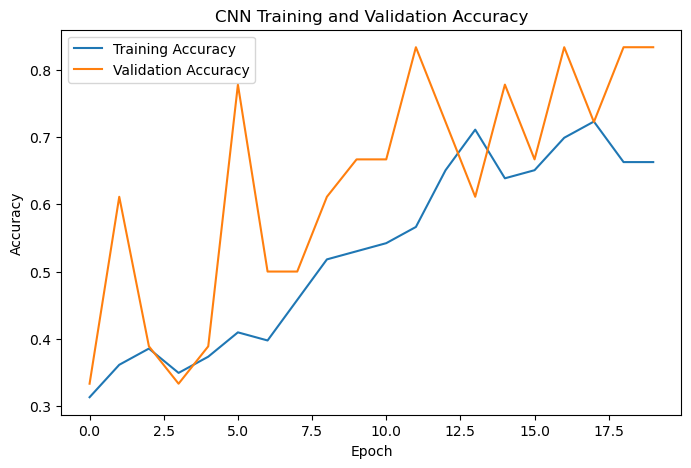

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### 6.5 CNN Training and Validation Loss

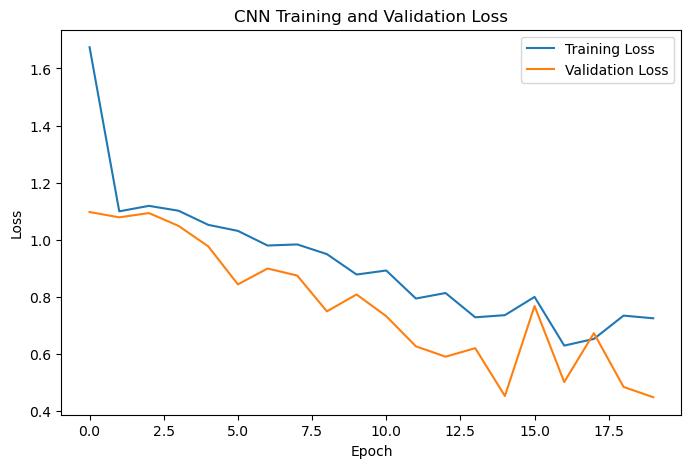

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### 6.6 MobileNetV2 Transfer Learning

In [21]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

mobilenet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax")
])

mobilenet_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 6.7 MobileNetV2 Training

In [25]:
mobilenet_history = mobilenet_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=15,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.3373 - loss: 1.4269 - val_accuracy: 0.4444 - val_loss: 1.0741 - learning_rate: 0.0010
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.4819 - loss: 1.1242 - val_accuracy: 0.5556 - val_loss: 0.8219 - learning_rate: 0.0010
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.6506 - loss: 0.7851 - val_accuracy: 0.8333 - val_loss: 0.6315 - learning_rate: 0.0010
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.6386 - loss: 0.7235 - val_accuracy: 0.8333 - val_loss: 0.5254 - learning_rate: 0.0010
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.7349 - loss: 0.7317 - val_accuracy: 0.8889 - val_loss: 0.4338 - learning_rate: 0.0010
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.6867 - loss: 0.6567 - val_accuracy: 0.9444 - val_loss: 0.3767 - learning_rate: 0.0010
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.8072 - loss: 0.5172 - val_accuracy: 1.0000 - val_loss

### 6.8 MobileNetV2 Training and Validation Accuracy

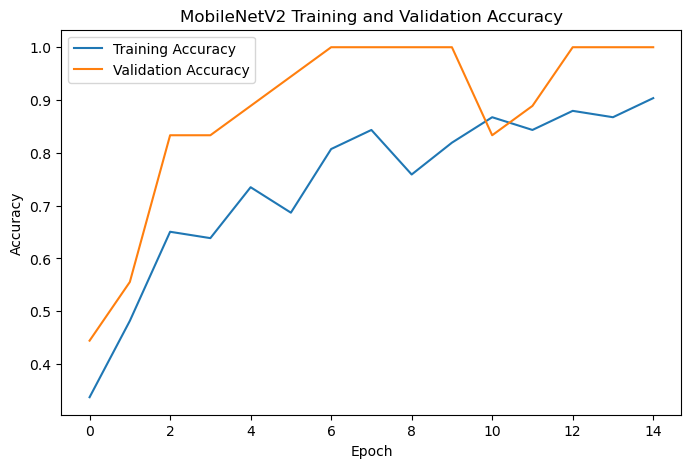

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(mobilenet_history.history["accuracy"], label="Training Accuracy")
plt.plot(mobilenet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### 6.9 MobileNetV2 Training  and Validation Loss

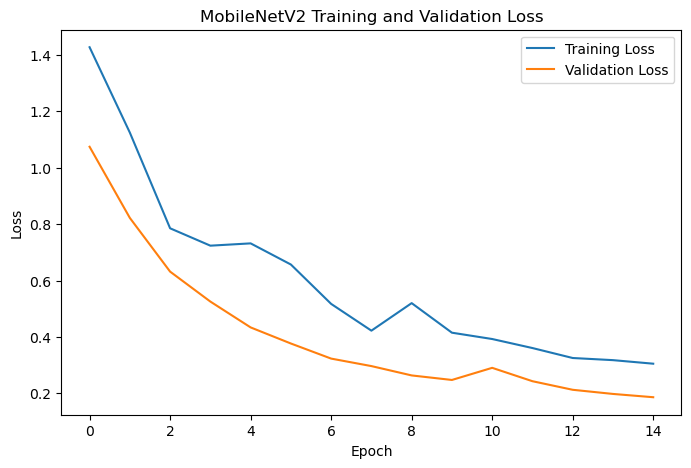

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(mobilenet_history.history["loss"], label="Training Loss")
plt.plot(mobilenet_history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## 7. Model Evaluation

In [28]:
def evaluate_model(model, generator):
    generator.reset()
    probabilities = model.predict(generator)
    predictions = np.argmax(probabilities, axis=1)
    true_labels = generator.classes

    accuracy = accuracy_score(true_labels, predictions)
    precision = precision_score(
        true_labels, predictions,
        average="weighted", zero_division=0
    )
    recall = recall_score(
        true_labels, predictions,
        average="weighted", zero_division=0
    )
    f1 = f1_score(
        true_labels, predictions,
        average="weighted", zero_division=0
    )

    return accuracy, precision, recall, f1, predictions

### 7.1  Evaluate Both Models

In [29]:
cnn_accuracy, cnn_precision, cnn_recall, cnn_f1, cnn_predictions = evaluate_model(
    cnn_model, test_generator
)

mobilenet_accuracy, mobilenet_precision, mobilenet_recall, mobilenet_f1, mobilenet_predictions = evaluate_model(
    mobilenet_model, test_generator
)

comparison = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Accuracy": [cnn_accuracy, mobilenet_accuracy],
    "Precision": [cnn_precision, mobilenet_precision],
    "Recall": [cnn_recall, mobilenet_recall],
    "F1 Score": [cnn_f1, mobilenet_f1]
})

comparison

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 246ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step


,Model,Accuracy,Precision,Recall,F1 Score
0,Custom CNN,0.555556,0.574074,0.555556,0.537037
1,MobileNetV2,0.833333,0.849206,0.833333,0.837218


### 7.2 Classification Reports

In [30]:
print("Custom CNN Classification Report:")
print(
    classification_report(
        test_generator.classes,
        cnn_predictions,
        target_names=test_generator.class_indices.keys(),
        zero_division=0
    )
)

print("\nMobileNetV2 Classification Report:")
print(
    classification_report(
        test_generator.classes,
        mobilenet_predictions,
        target_names=test_generator.class_indices.keys(),
        zero_division=0
    )
)

Custom CNN Classification Report:
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.50      0.50      0.50         6
           Brown Spot       0.67      0.33      0.44         6
            Leaf Smut       0.56      0.83      0.67         6

             accuracy                           0.56        18
            macro avg       0.57      0.56      0.54        18
         weighted avg       0.57      0.56      0.54        18


MobileNetV2 Classification Report:
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.83      0.83      0.83         6
           Brown Spot       0.71      0.83      0.77         6
            Leaf Smut       1.00      0.83      0.91         6

             accuracy                           0.83        18
            macro avg       0.85      0.83      0.84        18
         weighted avg       0.85      0.83      0.84        18



### 7.3 Confusion Matrix - Custom CNN

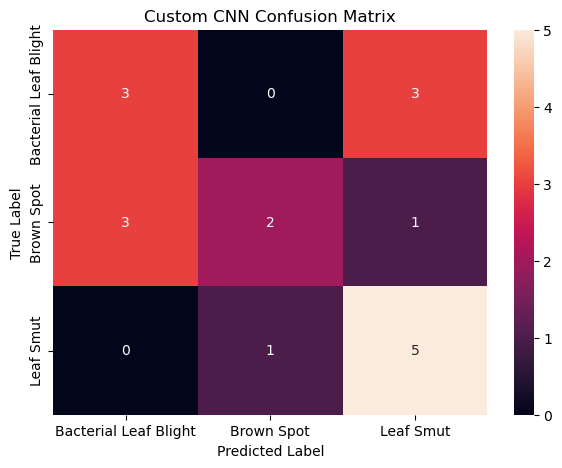

In [31]:
cm_cnn = confusion_matrix(
    test_generator.classes,
    cnn_predictions
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_cnn,
    annot=True,
    fmt="d",
    xticklabels=test_generator.class_indices.keys(),
    yticklabels=test_generator.class_indices.keys()
)
plt.title("Custom CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

### 7.4 Confusion Matrix - MobileNetV2

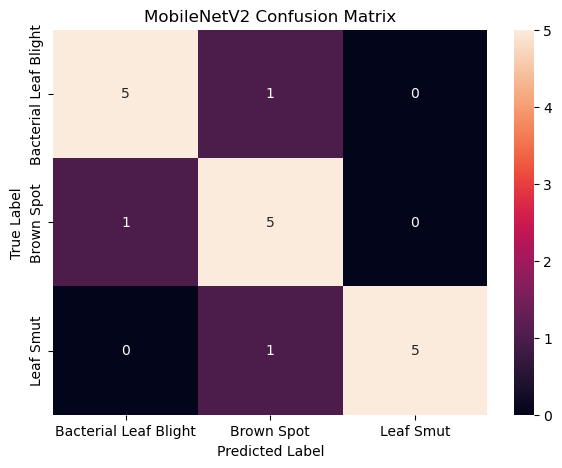

In [32]:
cm_mobilenet = confusion_matrix(
    test_generator.classes,
    mobilenet_predictions
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_mobilenet,
    annot=True,
    fmt="d",
    xticklabels=test_generator.class_indices.keys(),
    yticklabels=test_generator.class_indices.keys()
)
plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## 8. Model Comparison

In [33]:
comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Custom CNN,0.555556,0.574074,0.555556,0.537037
1,MobileNetV2,0.833333,0.849206,0.833333,0.837218


### 8.1 Best Model

In [34]:
best_model_name = comparison.loc[
    comparison["F1 Score"].idxmax(), "Model"
]

best_accuracy = comparison.loc[
    comparison["F1 Score"].idxmax(), "Accuracy"
]

best_f1 = comparison["F1 Score"].max()

print("Best Model:", best_model_name)
print("Accuracy:", best_accuracy)
print("F1 Score:", best_f1)

Best Model: MobileNetV2
Accuracy: 0.8333333333333334
F1 Score: 0.8372183372183373


# 9. Challenges Faced and Solutions

- Limited dataset size: Data augmentation was used to improve model generalization.
- Different image dimensions: Images were resized to 224 × 224 pixels.
- Limited dataset size: Data augmentation and transfer learning were used to improve model generalization.
- Model overfitting: Dropout, Early Stopping, and learning-rate reduction were used.
- Disease classification complexity: CNN and MobileNetV2 were compared to identify the better-performing model.

## 10. Conclusion

This project developed a deep learning-based system for classifying rice leaf diseases. Custom CNN and MobileNetV2 models were trained and evaluated using accuracy, precision, recall, F1 score, classification reports, and confusion matrices. The better-performing model was selected based on F1 score for reliable disease classification.

## 11. Save Best Model

In [ ]:
if best_model_name == "Custom CNN":
    best_model = cnn_model
else:
    best_model = mobilenet_model

best_model.save("best_rice_leaf_disease_model.keras")

print("Best model saved successfully.")
print("Model:", best_model_name)